# Лабораторная работа №4: Self-supervised learning визуальных представлений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Извлечь frozen DINO embeddings.
- Сравнить k-NN и linear probe при 1/10/100% меток.
- Исследовать ближайших соседей и shortcut features.


## Теоретическая часть

Self-supervised encoder обучается без классов: contrastive objective сближает представления двух views одного изображения, masked modeling восстанавливает скрытые токены. Качество representation проверяют frozen k-NN и linear probe.

![DINO](https://raw.githubusercontent.com/facebookresearch/dino/main/.github/dino.gif)


### Математическая постановка

InfoNCE для пары $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.$$
Linear probe обучает только $W$ в $\hat y=\arg\max Wz$.


### Материалы

- [DINOv2](https://github.com/facebookresearch/dinov2)
- [SimCLR](https://arxiv.org/abs/2002.05709)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Извлечь frozen DINO embeddings.
2. Сравнить k-NN и linear probe при 1/10/100% меток.
3. Исследовать ближайших соседей и shortcut features.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** DINOv2 ViT-S/14 frozen, FP16.
- **Ограничение данных:** до 5 000 изображений.
- **Fallback:** ResNet18 frozen embeddings.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\eric1\\Desktop\\data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Стратифицированные разбиения CIFAR-10

*Вес: 1 балл.*

**Постановка.** Train, validation и test изолируют подбор параметров линейного probe.

Выполните следующие действия:
1. Загрузите CIFAR-10 и стратифицируйте train.
2. Подготовьте неизменяемые индексы test.

**Результат.** Датасет ds, загрузчик loader и длины трёх выборок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
import torch
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split

# CIFAR-10 скачается один раз в <корень курса>/data (~170 МБ)
base_train = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)
base_test  = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)

y_all = np.array(base_train.targets)
train_idx, val_idx = train_test_split(
    np.arange(len(y_all)), test_size=0.1, stratify=y_all, random_state=SEED
)
test_idx = np.arange(len(base_test.targets))

if FAST_DEV_RUN:
    train_idx, val_idx, test_idx = train_idx[:200], val_idx[:100], test_idx[:100]
else:
    train_idx, val_idx, test_idx = train_idx[:5000], val_idx[:1000], test_idx[:2000]  # лимит профиля

# Энкодер ждёт 224x224 и ImageNet-нормализацию
ENC_SIZE = 224
eval_tf = T.Compose([
    T.Resize((ENC_SIZE, ENC_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class ImagesWithLabels(Dataset):
    def __init__(self, base, indices, tf):
        self.base, self.idx, self.tf = base, list(map(int, indices)), tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        img, y = self.base[self.idx[i]]
        return self.tf(img), y

ds_train = ImagesWithLabels(base_train, train_idx, eval_tf)
ds_val   = ImagesWithLabels(base_train, val_idx,   eval_tf)
ds_test  = ImagesWithLabels(base_test,  test_idx,  eval_tf)

with open(ARTIFACTS / "dataset_manifest.json", "w") as f:
    json.dump({"train": len(ds_train), "val": len(ds_val), "test": len(ds_test)}, f, indent=4)
print({"train": len(ds_train), "val": len(ds_val), "test": len(ds_test)})
check(len(set(train_idx) & set(val_idx)) == 0, "Train и val не пересекаются")

100%|██████████| 170M/170M [57:59<00:00, 49.0kB/s]   


{'train': 5000, 'val': 1000, 'test': 2000}
✔ Train и val не пересекаются


### Предобученный DINOv2 и признаки

*Вес: 1 балл.*

**Постановка.** Frozen encoder предоставляет представления без доступа к меткам при извлечении.

Выполните следующие действия:
1. Загрузите DINOv2 ViT-S/14.
2. Сохраните нормированные признаки и явные train/validation/test индексы.

**Результат.** embeddings.npz с фактическими DINO-признаками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
use_dino = True
try:
    encoder = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', trust_repo=True)
    encoder.eval().to(DEVICE)
    FEAT_DIM, ENCODER_NAME = 384, "dinov2_vits14"
except Exception as e:
    print(f"DINOv2 недоступен ({e}) — fallback на ResNet18 (предусмотрено профилем лабы)")
    use_dino = False
    from torchvision.models import resnet18, ResNet18_Weights
    encoder = resnet18(weights=ResNet18_Weights.DEFAULT)
    encoder.fc = torch.nn.Identity()
    encoder.eval().to(DEVICE)
    FEAT_DIM, ENCODER_NAME = 512, "resnet18"

# FP16 ускоряет только Volta+ (GTX 10xx = Pascal 6.1), поэтому там fp32
USE_FP16 = DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 7

@torch.no_grad()
def extract_features(dataset, batch_size=64):
    feats, labels = [], []
    for imgs, ys in DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0):
        imgs = imgs.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_FP16):
            f = encoder(imgs)
        feats.append(f.float().cpu())
        labels.append(torch.as_tensor(ys))
    F_all = torch.nn.functional.normalize(torch.cat(feats), dim=1)  # L2-нормировка
    return F_all.numpy().astype(np.float32), torch.cat(labels).numpy()

t0 = time.time()
X_train, y_train = extract_features(ds_train)
X_val,   y_val   = extract_features(ds_val)
X_test,  y_test  = extract_features(ds_test)
print(f"Признаки за {time.time()-t0:.1f}s: train {X_train.shape}, val {X_val.shape}, test {X_test.shape}")

np.savez_compressed(ARTIFACTS / "embeddings.npz",
    X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test,
    train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)
with open(ARTIFACTS / "encoder_meta.json", "w") as f:
    json.dump({"encoder": ENCODER_NAME, "feat_dim": FEAT_DIM, "fp16": bool(USE_FP16)}, f, indent=4)
check(True, "embeddings.npz сохранён")

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to C:\Users\eric1/.cache\torch\hub\main.zip
C:\Users\eric1/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\eric1/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\eric1/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to C:\Users\eric1/.cache\torch\hub\checkpoints\dinov2_vits14_pretrain.pth
100%|██████████| 84.2M/84.2M [00:08<00:00, 10.9MB/s]


Признаки за 104.1s: train (5000, 384), val (1000, 384), test (2000, 384)
✔ embeddings.npz сохранён


### Подбор k-NN на validation

*Вес: 1 балл.*

**Постановка.** Число соседей следует выбирать без обращения к test.

Выполните следующие действия:
1. Обучите k-NN для предложенной сетки k.
2. Выберите k по validation accuracy.

**Результат.** Словарь knn_val и выбранный best_k.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
from sklearn.neighbors import KNeighborsClassifier

k_grid = [1, 3, 5, 10, 20, 50]
knn_val = {}
for k in k_grid:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1).fit(X_train, y_train)
    knn_val[k] = float((knn.predict(X_val) == y_val).mean())
    print(f"k={k}: val acc {knn_val[k]:.4f}")

best_k = max(knn_val, key=knn_val.get)
print(f"best_k = {best_k}")
check(True, f"k выбран по validation, test не трогали: best_k={best_k}")


k=1: val acc 0.9120
k=3: val acc 0.9240
k=5: val acc 0.9410
k=10: val acc 0.9240
k=20: val acc 0.9290
k=50: val acc 0.9280
best_k = 5
✔ k выбран по validation, test не трогали: best_k=5


### Линейная проверка и test

*Вес: 1 балл.*

**Постановка.** Frozen-признаки оценивают независимыми простыми классификаторами.

Выполните следующие действия:
1. Обучите k-NN и logistic regression только на train.
2. Вычислите test accuracy и macro-F1 после выбора k.

**Результат.** probes.json с измеренными test-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

pred_knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_train, y_train).predict(X_test)
lin = LogisticRegression(max_iter=2000).fit(X_train, y_train)
pred_lin = lin.predict(X_test)

probes = {
    "encoder": ENCODER_NAME,
    "best_k": int(best_k),
    "knn_test_acc": float(accuracy_score(y_test, pred_knn)),
    "knn_test_macro_f1": float(f1_score(y_test, pred_knn, average="macro")),
    "linear_test_acc": float(accuracy_score(y_test, pred_lin)),
    "linear_test_macro_f1": float(f1_score(y_test, pred_lin, average="macro")),
}
with open(ARTIFACTS / "probes.json", "w") as f:
    json.dump(probes, f, indent=4)
print(probes)
check(True, "probes.json сохранён")


{'encoder': 'dinov2_vits14', 'best_k': 5, 'knn_test_acc': 0.928, 'knn_test_macro_f1': 0.9269233107018383, 'linear_test_acc': 0.955, 'linear_test_macro_f1': 0.9544075042873779}
✔ probes.json сохранён


### Кривая объёма разметки

*Вес: 1 балл.*

**Постановка.** Малые размеченные подмножества выявляют sample efficiency представления.

Выполните следующие действия:
1. Создайте сбалансированные подмножества train по фиксированному seed.
2. Обучите отдельный linear probe для каждой доли и сохраните результаты.

**Результат.** label_curve.json с числом объектов и измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
fractions = [0.01, 0.1, 1.0]
rng = np.random.RandomState(SEED)
label_curve = []

for fr in fractions:
    per_class = max(1, int(round(fr * len(y_train) / 10)))  # сбалансированно по классам
    sel = []
    for c in range(10):
        local = np.where(y_train == c)[0]
        sel.extend(rng.choice(local, size=min(per_class, len(local)), replace=False))
    sel = np.array(sel)
    clf = LogisticRegression(max_iter=2000).fit(X_train[sel], y_train[sel])
    acc = float(accuracy_score(y_test, clf.predict(X_test)))
    label_curve.append({"fraction": fr, "n_labeled": int(len(sel)), "test_acc": acc})
    print(f"{int(fr*100)}% ({len(sel)} меток): test acc {acc:.4f}")

with open(ARTIFACTS / "label_curve.json", "w") as f:
    json.dump(label_curve, f, indent=4)
check(True, "label_curve.json сохранён")


1% (50 меток): test acc 0.8545
10% (500 меток): test acc 0.9335
100% (4945 меток): test acc 0.9545
✔ label_curve.json сохранён


### Контрастивная адаптация encoder

*Вес: 1 балл.*

**Постановка.** Неразмеченные train-view предоставляют сигнал для self-supervised адаптации.

Выполните следующие действия:
1. Создайте две аугментации одних train-изображений.
2. Оптимизируйте InfoNCE и сохраните обновлённый encoder.

**Результат.** encoder_adapted.pt после реальных optimizer steps.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
import torch.nn as nn
import torch.nn.functional as F

contrast_tf = T.Compose([
    T.RandomResizedCrop(ENC_SIZE, scale=(0.5, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomApply([T.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
    T.RandomGrayscale(p=0.2),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class TwoViews(Dataset):
    def __init__(self, base, indices, tf):
        self.base, self.idx, self.tf = base, list(map(int, indices)), tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        img, _ = self.base[self.idx[i]]
        return self.tf(img), self.tf(img)  # два разных view одного изображения

# Учим только последний блок + проекционную голову: экономит 4 ГБ памяти
# и не даёт «забыть» предобученные признаки полностью
for p in encoder.parameters():
    p.requires_grad = False
if use_dino:
    for p in encoder.blocks[-1].parameters(): p.requires_grad = True
    for p in encoder.norm.parameters():       p.requires_grad = True
else:
    for p in encoder.layer4.parameters():     p.requires_grad = True

proj = nn.Linear(FEAT_DIM, 128).to(DEVICE)
encoder.eval()  # BN-статистики не обновляем

BS_CONTRAST = 24   # при CUDA out of memory уменьши до 16
TAU = 0.2
params = [p for p in encoder.parameters() if p.requires_grad] + list(proj.parameters())
opt = torch.optim.AdamW(params, lr=5e-5)
contrast_loader = DataLoader(TwoViews(base_train, train_idx, contrast_tf),
                             batch_size=BS_CONTRAST, shuffle=True, num_workers=0, drop_last=True)

def info_nce_loss(z1, z2, tau=TAU):
    z = F.normalize(torch.cat([z1, z2], dim=0), dim=1)
    sim = z @ z.T / tau
    n = z1.size(0)
    sim.fill_diagonal_(float("-inf"))
    targets = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(sim, targets)

t0, step, loss_avg = time.time(), 0, 0.0
for epoch in range(1):  # при желании полный режим можно гонять 2-3 эпохи
    for v1, v2 in contrast_loader:
        v1, v2 = v1.to(DEVICE), v2.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_FP16):
            z1, z2 = proj(encoder(v1)), proj(encoder(v2))
            loss = info_nce_loss(z1.float(), z2.float())
        opt.zero_grad(); loss.backward(); opt.step()
        loss_avg += loss.item(); step += 1
        if step % 50 == 0:
            print(f"step {step}, loss {loss_avg/50:.4f}, {time.time()-t0:.0f}s")
            loss_avg = 0.0

torch.save(encoder.state_dict(), ARTIFACTS / "encoder_adapted.pt")
check(step > 0, f"Encoder адаптирован ({step} optimizer steps), веса сохранены")

step 50, loss 1.0114, 46s
step 100, loss 0.8969, 91s
step 150, loss 0.8401, 137s
step 200, loss 0.8068, 182s
✔ Encoder адаптирован (208 optimizer steps), веса сохранены


### Признаки после адаптации

*Вес: 1 балл.*

**Постановка.** Сравнение до и после адаптации требует одних и тех же изображений.

Выполните следующие действия:
1. Пересчитайте признаки train/validation/test обновлённым encoder.
2. Обучите новый linear probe на train.

**Результат.** Матрица X_new и обученный new_linear.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
X_train_new, _ = extract_features(ds_train)
X_val_new,   _ = extract_features(ds_val)
X_test_new,  _ = extract_features(ds_test)

new_linear = LogisticRegression(max_iter=2000).fit(X_train_new, y_train)

np.savez_compressed(ARTIFACTS / "embeddings_adapted.npz",
                    X_train=X_train_new, X_val=X_val_new, X_test=X_test_new,
                    y_train=y_train, y_val=y_val, y_test=y_test)
check(True, "Признаки пересчитаны, new_linear обучен")


✔ Признаки пересчитаны, new_linear обучен


### Точность адаптированного probe

*Вес: 1 балл.*

**Постановка.** Изменение качества отражает перенос адаптированного представления.

Выполните следующие действия:
1. Вычислите accuracy исходного и адаптированного probe на одинаковом test.
2. Сохраните парный результат.

**Результат.** adaptation.json с наблюдаемыми показателями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
acc_before = float(accuracy_score(y_test, lin.predict(X_test)))
acc_after  = float(accuracy_score(y_test, new_linear.predict(X_test_new)))

adaptation = {
    "encoder": ENCODER_NAME,
    "test_acc_before": acc_before,
    "test_acc_after": acc_after,
    "delta": acc_after - acc_before,
}
with open(ARTIFACTS / "adaptation.json", "w") as f:
    json.dump(adaptation, f, indent=4)
print(adaptation)
check(True, "adaptation.json сохранён")

{'encoder': 'dinov2_vits14', 'test_acc_before': 0.955, 'test_acc_after': 0.9575, 'delta': 0.0025000000000000577}
✔ adaptation.json сохранён


### Визуальные соседи

*Вес: 1 балл.*

**Постановка.** Ранжирование соседей позволяет выявить смешение категорий.

Выполните следующие действия:
1. Найдите ближайшие train-объекты для фиксированных test-запросов.
2. Сохраните расстояния, индексы и метки.

**Результат.** neighbors.json с фактическими близкими изображениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
N_QUERIES = 10
query_local = np.arange(min(N_QUERIES, len(X_test)))
sims = X_test[query_local] @ X_train.T        # признаки нормированы -> косинусная близость
nn_local = np.argsort(-sims, axis=1)[:, :5]

neighbors = []
for qi, ql in enumerate(query_local):
    neighbors.append({
        "test_idx": int(test_idx[ql]),
        "query_label": int(y_test[ql]),
        "neighbors": [
            {"train_idx": int(train_idx[li]), "label": int(y_train[li]),
             "similarity": float(sims[qi, li])}
            for li in nn_local[qi]
        ],
    })

with open(ARTIFACTS / "neighbors.json", "w") as f:
    json.dump(neighbors, f, indent=4)
check(True, f"neighbors.json сохранён ({len(neighbors)} запросов)")

✔ neighbors.json сохранён (10 запросов)


### Чистота ближайшего окружения

*Вес: 1 балл.*

**Постановка.** Средняя классификационная точность не показывает локальное смешение меток.

Выполните следующие действия:
1. По уже вычисленным пяти соседям найдите долю совпадений классов.
2. Выведите среднюю чистоту и примеры с минимальной чистотой.

**Результат.** neighborhood_purity.json с измерениями на test-запросах.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
# Чистоту считаем по всем test-запросам, чтобы статистика была честной
sims_all  = X_test @ X_train.T
nn5_local = np.argsort(-sims_all, axis=1)[:, :5]
purity_vec = (y_train[nn5_local] == y_test[:, None]).sum(axis=1) / 5.0

purity = {
    "n_queries": int(len(purity_vec)),
    "mean_purity": float(purity_vec.mean()),
    "min_purity": float(purity_vec.min()),
    "worst_queries": [
        {"test_idx": int(test_idx[i]), "query_label": int(y_test[i]), "purity": float(purity_vec[i])}
        for i in np.argsort(purity_vec)[:3]
    ],
}
with open(ARTIFACTS / "neighborhood_purity.json", "w") as f:
    json.dump(purity, f, indent=4)
print(purity)
check(True, "neighborhood_purity.json сохранён")

{'n_queries': 2000, 'mean_purity': 0.8969, 'min_purity': 0.0, 'worst_queries': [{'test_idx': 1969, 'query_label': 1, 'purity': 0.0}, {'test_idx': 537, 'query_label': 2, 'purity': 0.0}, {'test_idx': 1862, 'query_label': 5, 'purity': 0.0}]}
✔ neighborhood_purity.json сохранён


### Творческий бонус: ошибки соседства

*Вес: 1 дополнительный балл.*

**Постановка.** Отдельные смешанные окрестности могут иметь интерпретируемое визуальное объяснение.

Выполните следующие действия:
1. Выберите два test-изображения с низкой чистотой соседей.
2. Сохраните коллаж запросов и соответствующих train-соседей.

**Результат.** bonus_neighbors.png и индексы изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


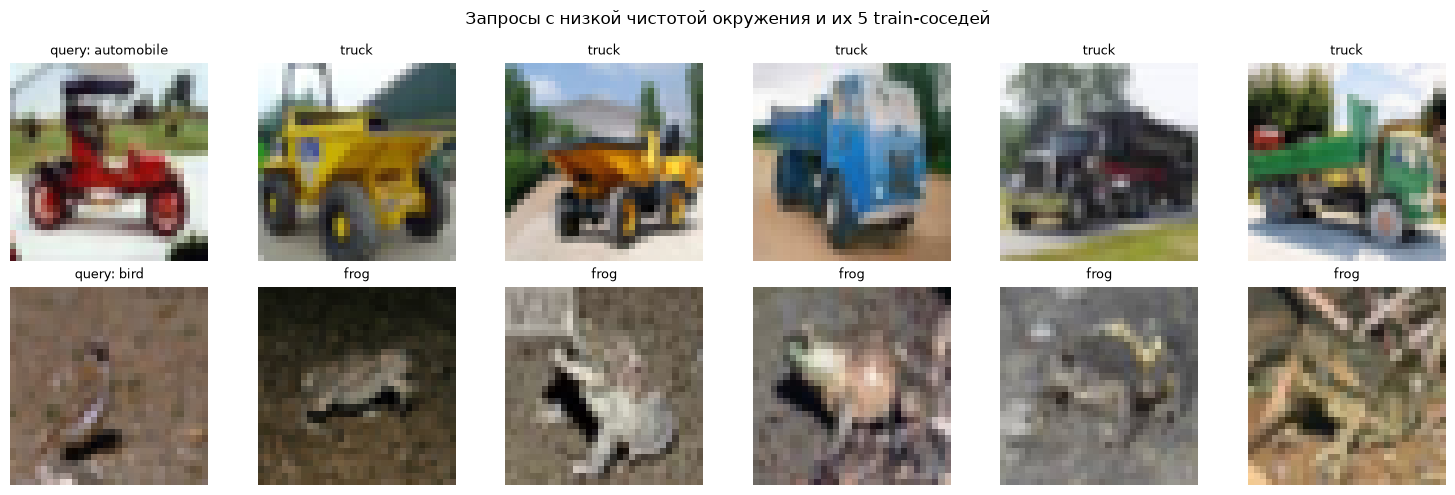

✔ Бонус: bonus_neighbors.png сохранён


In [13]:
import matplotlib.pyplot as plt

worst = np.argsort(purity_vec)[:2]
fig, axes = plt.subplots(2, 6, figsize=(15, 5))

for row, qi in enumerate(worst):
    axes[row, 0].imshow(base_test.data[test_idx[qi]])
    axes[row, 0].set_title(f"query: {base_test.classes[y_test[qi]]}", fontsize=9)
    for col, li in enumerate(nn5_local[qi]):
        axes[row, col + 1].imshow(base_train.data[train_idx[li]])
        axes[row, col + 1].set_title(base_train.classes[y_train[li]], fontsize=9)
for ax in axes.flat:
    ax.axis("off")

plt.suptitle("Запросы с низкой чистотой окружения и их 5 train-соседей")
plt.tight_layout()
plt.savefig(ARTIFACTS / "bonus_neighbors.png", dpi=150)
plt.show()

with open(ARTIFACTS / "bonus_neighbors.json", "w") as f:
    json.dump([{"test_idx": int(test_idx[qi]), "query_label": int(y_test[qi]),
                "neighbor_train_idx": [int(train_idx[li]) for li in nn5_local[qi]]} for qi in worst],
              f, indent=4)
check(True, "Бонус: bonus_neighbors.png сохранён")


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.
